# Steering Shifts Downstream Representations of the Intended Concepts

We test whether the steering interventions from `03_physical_concept_steering.ipynb` also shift the model's *internal linear representation* of the corresponding physical quantity.

For each concept, we reuse the exact block 1–4 CLS steering from the previous notebook and read out the ridge probes fit in `01_physical_concept_probes.ipynb` at **block 5**.We evaluate on a single fixed batch drawn evenly across all 10 JetClass classes.

## Setup

In [1]:
# ruff: noqa: E402
import json
import warnings

from tqdm import TqdmWarning
warnings.filterwarnings("ignore", category=TqdmWarning)

import joblib
import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

from jetdirections.config import (
    CHECKPOINT_DIR, DROPOUT, MODEL_DIM, NUM_CLASSES, NUM_HEADS,
    NUM_LAYERS, PROJ_ROOT, VAL_DATA_DIR,
)
from jetdirections.data.dataset import JetClassDataset
from jetdirections.data.sampling import load_stratified_batch
from jetdirections.interp import extract_cls_activations_with_steering
from jetdirections.model.transformer import JetTagTransformer

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
STEER_LAYERS = [1, 2, 3, 4]
READOUT_LAYER = 5
ALPHAS = [-8, -6, -4, -3, -2, -1.5, -1, -0.5, 0, 0.5, 1, 1.5, 2, 3, 4, 6, 8]
PER_CLASS = 5_000  # -> 50,000 jets total, evenly split across all 10 classes
EVAL_SEED = 2  # distinct from the QCD draws used to fit probes (01, seed=1) and directions (02, seed=0)

STEERING_DIR = PROJ_ROOT / "experiments" / "results" / "physical_concept_steering"
DIRECTIONS_DIR = STEERING_DIR / "directions"
PROBES_DIR = PROJ_ROOT / "experiments" / "results" / "physical_concept_probes"
RESULTS_DIR = PROJ_ROOT / "experiments" / "results" / "physical_concept_downstream_probes"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"device: {DEVICE}")

device: cuda


### Load Model

In [2]:
checkpoint = torch.load(CHECKPOINT_DIR / "jetclass_transformer.pt", map_location=DEVICE, weights_only=False)
model = JetTagTransformer(
    input_dim=17, embed_dim=MODEL_DIM, num_heads=NUM_HEADS,
    num_layers=NUM_LAYERS, num_classes=NUM_CLASSES, dropout=DROPOUT,
).to(DEVICE)
state = checkpoint["model_state_dict"] if "model_state_dict" in checkpoint else checkpoint
model.load_state_dict(state)
model.eval();

### Load Steering Directions and Fitted Probes

In [3]:
directions = {
    name: torch.load(DIRECTIONS_DIR / f"{name}_direction.pt", weights_only=True)
    for name in ("mass", "multiplicity", "charge", "displacement")
}

fitted_probes = joblib.load(PROBES_DIR / "fitted_probes.joblib")
CONCEPT_TO_PROBE_KEY = {
    "mass": "Jet Mass",
    "multiplicity": "Particle Multiplicity",
    "charge": "Jet Charge",
    "displacement": "Track Displacement",
}
probes = {
    name: fitted_probes[key][READOUT_LAYER].probe
    for name, key in CONCEPT_TO_PROBE_KEY.items()
}
for name, key in CONCEPT_TO_PROBE_KEY.items():
    r2 = fitted_probes[key][READOUT_LAYER].test_r2
    print(f"{name}: block-{READOUT_LAYER} probe held-out R^2 = {r2:.4f} (from 01)")

mass: block-5 probe held-out R^2 = 0.9833 (from 01)
multiplicity: block-5 probe held-out R^2 = 0.9892 (from 01)
charge: block-5 probe held-out R^2 = 0.9401 (from 01)
displacement: block-5 probe held-out R^2 = 0.8256 (from 01)


### Load Evaluation Batch

A single batch drawn evenly across all 10 classes, fixed once and reused for every $\alpha$ so each concept's curve tracks the same jets — isolating the effect of $\alpha$ from resampling noise.

In [4]:
dataset = JetClassDataset(VAL_DATA_DIR, shuffle_files=False)
eval_batch = load_stratified_batch(dataset, per_class=PER_CLASS, seed=EVAL_SEED)
x, mask, labels = eval_batch
assert len(x) == PER_CLASS * NUM_CLASSES
print(f"eval batch: {len(x):,} jets ({PER_CLASS:,} per class x {NUM_CLASSES} classes)")

eval batch: 50,000 jets (5,000 per class x 10 classes)


# Downstream Probe Sweep

In [5]:
CONCEPT_LABELS = {
    "mass": r"probe: $\log(\max(m/1\,\mathrm{GeV}, 1))$",
    "multiplicity": "probe: particle multiplicity",
    "charge": "probe: jet charge",
    "displacement": r"probe: $\log(1+S_{d_0})$",
}


def downstream_probe_sweep(vectors, probe):
    """Mean and std of the block-5 probe prediction on eval_batch, across ALPHAS.

    `vectors` is a {layer: (embed,)} dict of CLS steering directions at blocks 1-4
    (as saved by 02); the particle-token steering component is zero, matching the
    CLS-only intervention used for the section-4.2 decision-migration figures.
    """
    steering = {layer: (vector, torch.zeros_like(vector)) for layer, vector in vectors.items()}
    means, stds = [], []
    for alpha in ALPHAS:
        block5 = extract_cls_activations_with_steering(
            model, eval_batch, [READOUT_LAYER], steering, scale=float(alpha)
        )[READOUT_LAYER].numpy()
        predictions = probe.predict(block5)
        means.append(float(predictions.mean()))
        stds.append(float(predictions.std()))
    return np.array(means), np.array(stds)


sweep_results = {}
for name in ("mass", "multiplicity", "charge", "displacement"):
    means, stds = downstream_probe_sweep(directions[name], probes[name])
    sweep_results[name] = {"alphas": ALPHAS, "mean": means, "std": stds}
    zero = ALPHAS.index(0)
    print(f"{name}: block-{READOUT_LAYER} probe mean at alpha=0 is {means[zero]:.4f}, "
          f"ranges {means.min():.4f} to {means.max():.4f} over the sweep")

mass: block-5 probe mean at alpha=0 is 4.6290, ranges -30.5579 to 38.9713 over the sweep
multiplicity: block-5 probe mean at alpha=0 is 41.4814, ranges -796.4480 to 899.1371 over the sweep
charge: block-5 probe mean at alpha=0 is -0.0064, ranges -13.2822 to 12.9108 over the sweep
displacement: block-5 probe mean at alpha=0 is 4.4337, ranges -76.9161 to 84.6676 over the sweep


## Plot: Probe-Predicted Concept Value vs Steering Coefficient

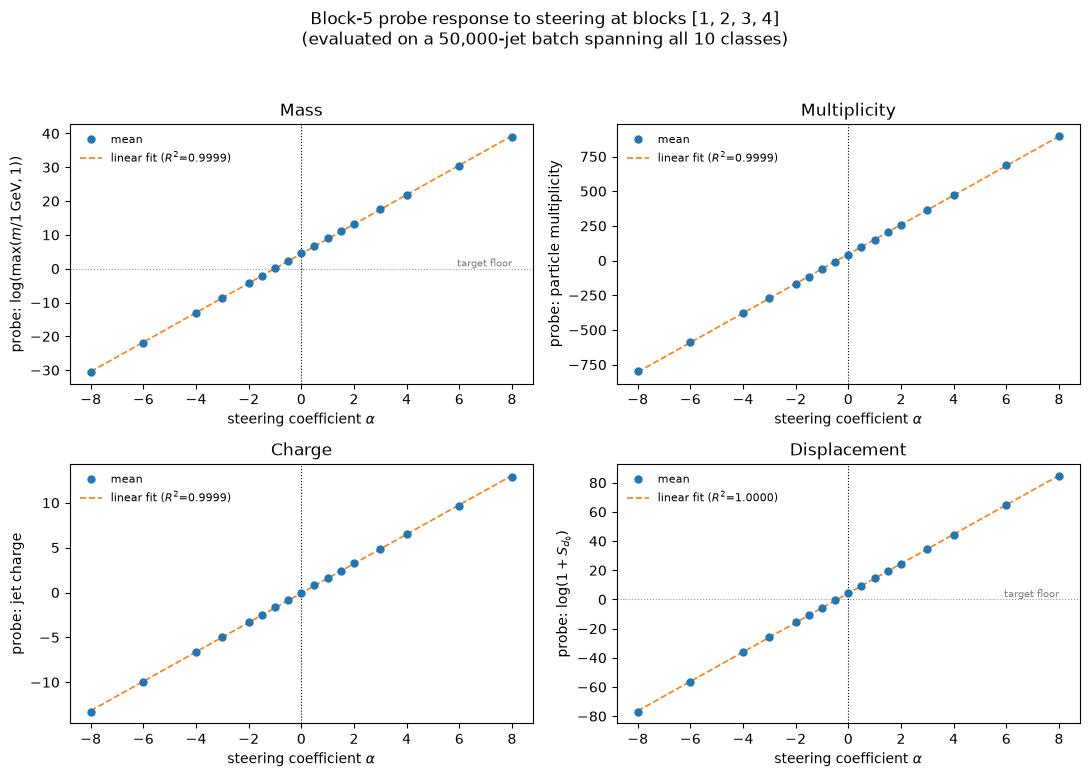

In [6]:
FLOOR_CONCEPTS = {"mass", "displacement"}  # target is log(...), floored at 0 by construction

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5))
for ax, name in zip(axes.flat, ("mass", "multiplicity", "charge", "displacement")):
    result = sweep_results[name]
    alphas = np.array(result["alphas"])
    means = result["mean"]

    ax.plot(alphas, means, "o", ms=5, color="C0", zorder=3, label="mean")
    slope, intercept = np.polyfit(alphas, means, 1)
    r2 = np.corrcoef(alphas, means)[0, 1] ** 2
    ax.plot(
        alphas, slope * alphas + intercept, "--", color="C1", lw=1.2,
        label=f"linear fit ($R^2$={r2:.4f})",
    )
    if name in FLOOR_CONCEPTS:
        ax.axhline(0, color="0.6", lw=0.8, ls=":")
        ax.text(alphas.max(), 0, " target floor", color="0.5", fontsize=7, va="bottom", ha="right")
    ax.axvline(0, color="k", lw=0.8, ls=":")

    ax.set_xlabel(r"steering coefficient $\alpha$")
    ax.set_ylabel(CONCEPT_LABELS[name])
    ax.set_title(name.capitalize())
    ax.legend(fontsize=8, frameon=False)

fig.suptitle(
    f"Block-{READOUT_LAYER} probe response to steering at blocks {STEER_LAYERS}\n"
    f"(evaluated on a {PER_CLASS * NUM_CLASSES:,}-jet batch spanning all {NUM_CLASSES} classes)",
    y=1.03,
)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "downstream_probe_response.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)

## Save Downstream Probe-Response Data

In [7]:
data = {
    name: {
        "alphas": result["alphas"],
        "mean": result["mean"].tolist(),
        "std": result["std"].tolist(),
        "probe_target": CONCEPT_LABELS[name],
        "readout_layer": READOUT_LAYER,
        "steer_layers": STEER_LAYERS,
    }
    for name, result in sweep_results.items()
}
(RESULTS_DIR / "downstream_probe_response.json").write_text(json.dumps(data, indent=2))

for name, result in data.items():
    header = "| $\\alpha$ | probe mean | probe std |"
    separator = "|---:|---:|---:|"
    rows = [header, separator]
    for alpha, mean, std in zip(result["alphas"], result["mean"], result["std"]):
        rows.append(f"| {alpha:g} | {mean:.4f} | {std:.4f} |")
    display(Markdown(f"### {name.capitalize()} steering: block-{READOUT_LAYER} probe response\n\n" + "\n".join(rows)))
    (RESULTS_DIR / f"{name}_downstream_probe_response.md").write_text("\n".join(rows) + "\n")

### Mass steering: block-5 probe response

| $\alpha$ | probe mean | probe std |
|---:|---:|---:|
| -8 | -30.5579 | 0.3981 |
| -6 | -21.8738 | 0.3970 |
| -4 | -13.1611 | 0.3993 |
| -3 | -8.7822 | 0.4080 |
| -2 | -4.3738 | 0.4312 |
| -1.5 | -2.1476 | 0.4486 |
| -1 | 0.1073 | 0.4549 |
| -0.5 | 2.3814 | 0.4474 |
| 0 | 4.6290 | 0.4387 |
| 0.5 | 6.8511 | 0.4303 |
| 1 | 9.0313 | 0.4260 |
| 1.5 | 11.1710 | 0.4148 |
| 2 | 13.2955 | 0.4033 |
| 3 | 17.5465 | 0.3871 |
| 4 | 21.8117 | 0.3784 |
| 6 | 30.3768 | 0.3721 |
| 8 | 38.9713 | 0.3706 |

### Multiplicity steering: block-5 probe response

| $\alpha$ | probe mean | probe std |
|---:|---:|---:|
| -8 | -796.4480 | 14.1552 |
| -6 | -586.5445 | 14.1160 |
| -4 | -376.7073 | 14.1651 |
| -3 | -272.0844 | 14.4118 |
| -2 | -167.9655 | 15.1298 |
| -1.5 | -116.0847 | 15.6271 |
| -1 | -64.1201 | 15.9809 |
| -0.5 | -11.7459 | 16.2101 |
| 0 | 41.4814 | 16.5917 |
| 0.5 | 95.0146 | 17.0037 |
| 1 | 148.8623 | 17.4628 |
| 1.5 | 203.3648 | 17.5991 |
| 2 | 257.8947 | 17.5230 |
| 3 | 366.2390 | 17.2394 |
| 4 | 473.8041 | 16.9124 |
| 6 | 687.2482 | 16.2092 |
| 8 | 899.1371 | 15.6111 |

### Charge steering: block-5 probe response

| $\alpha$ | probe mean | probe std |
|---:|---:|---:|
| -8 | -13.2822 | 0.2722 |
| -6 | -9.9769 | 0.2744 |
| -4 | -6.6549 | 0.2782 |
| -3 | -4.9886 | 0.2808 |
| -2 | -3.3211 | 0.2841 |
| -1.5 | -2.4884 | 0.2855 |
| -1 | -1.6577 | 0.2858 |
| -0.5 | -0.8301 | 0.2845 |
| 0 | -0.0064 | 0.2818 |
| 0.5 | 0.8129 | 0.2792 |
| 1 | 1.6286 | 0.2769 |
| 1.5 | 2.4417 | 0.2743 |
| 2 | 3.2524 | 0.2708 |
| 3 | 4.8669 | 0.2628 |
| 4 | 6.4763 | 0.2559 |
| 6 | 9.6915 | 0.2480 |
| 8 | 12.9108 | 0.2473 |

### Displacement steering: block-5 probe response

| $\alpha$ | probe mean | probe std |
|---:|---:|---:|
| -8 | -76.9161 | 2.3449 |
| -6 | -56.3687 | 2.2356 |
| -4 | -35.9910 | 2.1355 |
| -3 | -25.8526 | 2.1197 |
| -2 | -15.7368 | 2.1289 |
| -1.5 | -10.6862 | 2.1401 |
| -1 | -5.6405 | 2.1537 |
| -0.5 | -0.6003 | 2.1682 |
| 0 | 4.4337 | 2.1826 |
| 0.5 | 9.4610 | 2.1959 |
| 1 | 14.4812 | 2.2076 |
| 1.5 | 19.4942 | 2.2175 |
| 2 | 24.5010 | 2.2258 |
| 3 | 34.5032 | 2.2382 |
| 4 | 44.5056 | 2.2463 |
| 6 | 64.5609 | 2.2428 |
| 8 | 84.6676 | 2.2028 |